# Jalon 2 — Variante : écarter les objets ambigus de l'apprentissage

Ce notebook reprend l'heuristique du notebook `jalon2_2mrsort.ipynb` : partition aléatoire, un modèle lincs par segment, puis réaffectation par la marge. Il ne change qu'une chose : **sur certaines itérations, les objets ambigus ne servent pas à apprendre les modèles**.

Un objet est **ambigu** quand les deux modèles de l'itération précédente le classent correctement. Pour lui, $(x, y)$ est compatible avec les deux segments, et rien dans les données ne dit d'où il vient. S'il est gardé dans l'apprentissage, il pèse sur le modèle du segment où le hasard ou la marge l'a placé. S'il est retiré, chaque modèle apprend sur les objets qui **distinguent** son segment de l'autre.

Les hypothèses sont celles du notebook principal : features dans $[0, 1]$ à maximiser, catégories ordonnées de façon croissante, 2 segments de taille inconnue. L'algorithme n'utilise ni la proportion des segments ni le niveau de bruit. Les champs `rep` et `noise` du nom de fichier ne servent qu'à **évaluer** les résultats (section 4).

**Deux ajouts contre le surapprentissage** (sections 2 et 3) :
- **Arrêt sur un jeu de validation.** Une partie des objets d'apprentissage ne sert qu'à surveiller la généralisation. On garde l'itération où la précision de validation est la meilleure, et on s'arrête quand elle ne progresse plus. Cela remplace le seuil fixe de 0,97 sur la précision d'apprentissage.
- **Temps de lincs adapté à la taille du modèle.** Un modèle à 10 critères et 5 catégories a environ 2,7 fois plus de paramètres qu'un modèle à 6 critères et 3 catégories : il reçoit proportionnellement plus de temps.

In [18]:
import io
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lincs.classification as lc

DATA_DIR = Path("Datasets-Step2")

## 1. Fonctions reprises du notebook principal

Elles sont identiques au notebook principal :
- le chargement d'un jeu de données (`problem.yml` complété par `kind`) ;
- l'apprentissage d'un modèle MR-Sort avec lincs (*weights-profiles-breed*) ;
- la prédiction ;
- la marge d'un objet pour un modèle (poids normalisés, calcul en float32 comme lincs).

In [19]:
def load_dataset(csv_path):
    csv_path = Path(csv_path)
    yml = "kind: classification-problem\n" + (csv_path.parent / "problem.yml").read_text()
    problem = lc.Problem.load(io.StringIO(yml))
    df = pd.read_csv(csv_path)
    categories = [c.name for c in problem.ordered_categories]
    y = df["category"].astype(str).map(categories.index).to_numpy()
    return problem, df, y

def to_alternatives(problem, df):
    return lc.Alternatives.load(problem, io.StringIO(df.to_csv(index=False)))

In [20]:
def learn_mrsort(problem, df, seed=0, max_seconds=2):
    pls = lc.PreprocessedLearningSet(problem, to_alternatives(problem, df))
    models = lc.LearnMrsortByWeightsProfilesBreed.ModelsBeingLearned(pls, 9, seed)
    init = lc.InitializeProfilesForProbabilisticMaximalDiscriminationPowerPerCriterion(pls, models)
    weights = lc.OptimizeWeightsUsingGlop(pls, models)
    profiles = lc.ImproveProfilesWithAccuracyHeuristicOnCpu(pls, models)
    breed = lc.ReinitializeLeastAccurate(models, init, weights, 4)
    termination = lc.TerminateWhenAny([
        lc.TerminateAtAccuracy(models, len(df)),
        lc.TerminateAfterSeconds(max_seconds),
        lc.TerminateAfterIterationsWithoutProgress(models, 20),
    ])
    return lc.LearnMrsortByWeightsProfilesBreed(pls, models, init, weights, profiles, breed, termination).perform()

def predict(problem, model, df):
    alternatives = to_alternatives(problem, df)
    lc.classify_alternatives(problem, model, alternatives)
    return np.array([a.category_index for a in alternatives.alternatives])

In [21]:
def margins(problem, model, df, y, tol=1e-6):
    X = df[[c.name for c in problem.criteria]].to_numpy(dtype=np.float32)
    w = np.array(model.sufficient_coalitions[0].weights.criterion_weights, dtype=np.float64)
    b = np.array([[np.inf if t is None else t for t in av.real_thresholds.thresholds]
                  for av in model.accepted_values], dtype=np.float32).T     # (p-1, n)
    sigma = (X[:, None, :] >= b[None]) @ w                                   # (N, p-1)
    p, rows = b.shape[0] + 1, np.arange(len(y))
    low = np.where(y >= 1, sigma[rows, np.maximum(y - 1, 0)] - (1 - tol), np.inf)
    up = np.where(y <= p - 2, (1 - tol) - sigma[rows, np.minimum(y, p - 2)], np.inf)
    return np.minimum(low, up) / w.sum()

## 2. Heuristique avec exclusion des objets ambigus

**Découpage.** Au départ, on met de côté `val_size` = 20 % des objets reçus comme **jeu de validation**. Ces objets ne servent ni à apprendre les modèles, ni à la réaffectation : ils servent seulement à décider quand s'arrêter. Le reste forme le jeu d'apprentissage, partitionné au hasard en 2 segments.

À chaque itération :
1. **Apprentissage** : on apprend un modèle MR-Sort sur chaque segment. Si l'itération fait partie du calendrier d'exclusion, les objets jugés ambigus à l'itération précédente sont retirés de l'apprentissage.
2. **Évaluation** :
   - la précision d'apprentissage est la proportion d'objets bien classés par le modèle de leur segment, calculée sur **tous** les objets d'apprentissage, ambigus compris ;
   - la **précision de validation** est la proportion d'objets de validation bien classés par au moins un des deux modèles.
3. **Arrêt** : on mémorise l'itération dont la **précision de validation** est la meilleure. On s'arrête si elle n'a pas progressé depuis `patience` itérations, ou au bout de `max_iter` itérations. La fonction renvoie les modèles et la partition de cette meilleure itération.
4. **Ambiguïté** : un objet est ambigu si les deux modèles le classent bien. Cette information sert à l'itération suivante.
5. **Réaffectation par la marge** : tous les objets d'apprentissage, ambigus compris, changent de segment si l'autre modèle leur donne une marge strictement plus grande.

Les objets ambigus sont donc mis de côté **uniquement pour l'apprentissage**. Ils gardent un segment, et ils continuent d'être évalués et réaffectés.

**Pourquoi la validation.** La précision d'apprentissage monte presque toujours d'une itération à l'autre, car la réaffectation ajuste la partition au learning set, bruit compris. La précision de validation, elle, plafonne puis baisse quand l'algorithme commence à apprendre le bruit : c'est le bon moment pour s'arrêter. Avec 10 % de bruit, le seuil fixe de 0,97 n'était jamais atteint, et la boucle allait jusqu'à 20 itérations.

**Temps alloué à lincs** (`lincs_seconds`). Un modèle MR-Sort à $n$ critères et $p$ catégories a $n(p-1)$ seuils de profils, $n$ poids et 1 seuil de majorité. Le temps donné à lincs est proportionnel à ce nombre de paramètres, avec 2 s pour 6 critères et 3 catégories (19 paramètres). Cela donne environ 3,5 s pour 8 critères et 4 catégories, et 5,4 s pour 10 critères et 5 catégories. Ce calcul n'utilise que $n$ et $p$, qui font partie des entrées du problème.

**Calendrier d'exclusion** (paramètre `exclusion`) :
| Valeur | Itérations où les objets ambigus sont écartés |
|---|---|
| `"jamais"` | aucune : c'est l'algorithme du notebook principal, avec l'arrêt sur validation en plus (référence) |
| `"alternée"` | une itération sur deux (itérations impaires) |
| `"début"` | la première moitié des itérations, puis on les réintègre pour affiner les modèles sur toutes les données |
| `"toujours"` | toutes les itérations |

À la première itération, aucun objet n'est encore jugé ambigu, donc tous servent à l'apprentissage.

**Garde-fou** : si un segment compte moins de `min_train` objets une fois les ambigus retirés, on les garde pour ce segment. Cela évite d'apprendre un modèle sur une poignée d'objets.

In [22]:
def lincs_seconds(problem, base=2.0):
    n, p = len(problem.criteria), len(problem.ordered_categories)
    n_params = n * (p - 1) + n + 1                            # seuils des profils + poids + seuil de majorité
    return base * n_params / 19                                # 2 s pour 6 critères / 3 catégories

def excluded_at(it, exclusion, max_iter):
    return (exclusion == "toujours"
            or (exclusion == "alternée" and it % 2 == 1)
            or (exclusion == "début" and it < max_iter // 2))

def learn_2_mrsort_ambigus(problem, df, y, exclusion="alternée", val_size=0.2, patience=5, max_iter=20,
                           max_seconds=None, seed=0, min_train=10):
    rng = np.random.default_rng(seed)
    max_seconds = lincs_seconds(problem) if max_seconds is None else max_seconds

    val = np.zeros(len(df), bool)                              # jeu de validation
    val[rng.choice(len(df), int(val_size * len(df)), replace=False)] = True
    df_val, y_val = df[val].reset_index(drop=True), y[val]
    df, y = df[~val].reset_index(drop=True), y[~val]

    idx = np.arange(len(df))
    segment = rng.integers(0, 2, len(df))                     # partition aléatoire
    ambiguous = np.zeros(len(df), bool)                        # aucun objet ambigu au départ
    history, history_val, best = [], [], None

    for it in range(max_iter):
        models = []
        for k in (0, 1):                                       # 1. apprentissage
            train = segment == k
            if excluded_at(it, exclusion, max_iter) and (train & ~ambiguous).sum() >= min_train:
                train = train & ~ambiguous
            models.append(learn_mrsort(problem, df[train], seed + 2 * it + k, max_seconds))

        well_classified = np.array([predict(problem, m, df) for m in models]) == y     # 2. évaluation
        accuracy = well_classified[segment, idx].mean()
        val_accuracy = (np.array([predict(problem, m, df_val) for m in models]) == y_val).any(axis=0).mean()
        history.append(accuracy)
        history_val.append(val_accuracy)

        if best is None or val_accuracy > best["val_accuracy"]:                         # 3. arrêt
            best = dict(accuracy=accuracy, val_accuracy=val_accuracy, models=models,
                        segment=segment.copy(), iteration=it, well_classified=well_classified)
        elif it - best["iteration"] >= patience:
            break

        ambiguous = well_classified.all(axis=0)                # 4. ambiguïté
        margin = np.array([margins(problem, m, df, y) for m in models])
        move = margin[1 - segment, idx] > margin[segment, idx]                          # 5. réaffectation
        segment = np.where(move, 1 - segment, segment)

    best["history"], best["history_val"] = history, history_val
    return best

## 3. Mesures d'évaluation

La précision calculée pendant l'apprentissage est **optimiste** : chaque objet est jugé par le modèle du segment qu'on lui a choisi en connaissant sa catégorie. On découpe donc chaque fichier en trois parties :

| Partie | Part des objets | Exemple pour 300 objets | Rôle |
|---|---|---|---|
| apprentissage | 64 % | 192 | apprendre les modèles et la partition |
| validation | 16 % | 48 | choisir l'itération à retenir (section 2) |
| **test** | 20 % | 60 | mesurer la généralisation. Ces objets ne servent à **aucune** décision |

Le test reste indépendant de la validation. Sinon, en choisissant l'itération sur les objets de test, on mesurerait une précision trop optimiste.

Pour chaque essai, on mesure :
- **`train`** : la précision d'apprentissage à l'itération retenue ;
- **`val`** : la précision de validation à l'itération retenue ;
- **`test`** : la proportion d'objets de test bien classés par au moins un des deux modèles. **Un grand écart entre `train` et `test` signale du surapprentissage.** Avec 10 % de bruit, une précision `train` au-delà d'environ 0,91 apprend forcément du bruit ;
- **`petit_segment`** : la part du plus petit segment dans la partition retenue ;
- **`petit_discr`** : la même part, mais calculée **uniquement sur les objets discriminants**, ceux qu'un seul des deux modèles classe bien ;
- **`ambigus`** : la part des objets bien classés par les deux modèles ;
- **`petit_attendu`** : la part réelle du petit segment, lue dans le nom du fichier (`rep75-25` donne 0,25). Elle ne sert qu'à juger le résultat ;
- **`iter_retenue`** / **`iterations`** : l'itération retenue, et le nombre d'itérations effectuées avant l'arrêt.

Les jeux de validation et de test sont petits : sur un fichier de 300 objets, un objet de test vaut 1,7 point et un objet de validation 2,1 points.

In [23]:
def evaluate(csv_path, exclusion, seed=0, test_size=0.2, **kwargs):
    problem, df, y = load_dataset(csv_path)
    rng = np.random.default_rng(1000 + seed)
    test = np.zeros(len(df), bool)
    test[rng.choice(len(df), int(test_size * len(df)), replace=False)] = True
    df_train, y_train = df[~test].reset_index(drop=True), y[~test]
    df_test, y_test = df[test].reset_index(drop=True), y[test]

    start = time.time()
    res = learn_2_mrsort_ambigus(problem, df_train, y_train, exclusion=exclusion, seed=seed, **kwargs)
    ok_test = np.array([predict(problem, m, df_test) for m in res["models"]]) == y_test
    ok = res["well_classified"]
    discr = np.array([(ok[0] & ~ok[1]).sum(), (ok[1] & ~ok[0]).sum()])
    sizes = np.bincount(res["segment"], minlength=2)
    rep = int(re.search(r"rep(\d\d)", Path(csv_path).name).group(1))
    return dict(train=res["accuracy"], val=res["val_accuracy"], test=ok_test.any(axis=0).mean(),
                petit_segment=sizes.min() / sizes.sum(),
                petit_discr=discr.min() / discr.sum() if discr.sum() else np.nan,
                petit_attendu=min(rep, 100 - rep) / 100,
                ambigus=ok.all(axis=0).mean(),
                iter_retenue=res["iteration"] + 1, iterations=len(res["history"]),
                temps=time.time() - start)

## 4. Exemple sur un fichier

Le fichier `type_a/cr06_ca03/n0300_rep75-25_noise00` contient deux segments de 75 % et 25 %, sans bruit.

In [24]:
csv = DATA_DIR / "type_a/cr06_ca03/n0300_rep75-25_noise00.csv"
for exclusion in ["jamais", "alternée"]:
    print(f"{exclusion:9s}", {k: round(float(v), 3) for k, v in evaluate(csv, exclusion).items()})

jamais    {'train': 0.979, 'val': 0.896, 'test': 0.817, 'petit_segment': 0.38, 'petit_discr': 0.356, 'petit_attendu': 0.25, 'ambigus': 0.516, 'iter_retenue': 4.0, 'iterations': 9.0, 'temps': 4.398}
alternée  {'train': 0.99, 'val': 0.896, 'test': 0.867, 'petit_segment': 0.359, 'petit_discr': 0.436, 'petit_attendu': 0.25, 'ambigus': 0.417, 'iter_retenue': 5.0, 'iterations': 10.0, 'temps': 3.115}


### Courbes d'apprentissage et de validation

Sur un fichier **bruité** (`type_a/cr06_ca03/n0300_rep75-25_noise10`), on trace les deux précisions à chaque itération. L'écart qui se creuse entre les deux courbes montre le surapprentissage. Le point marque l'itération retenue grâce à la validation.

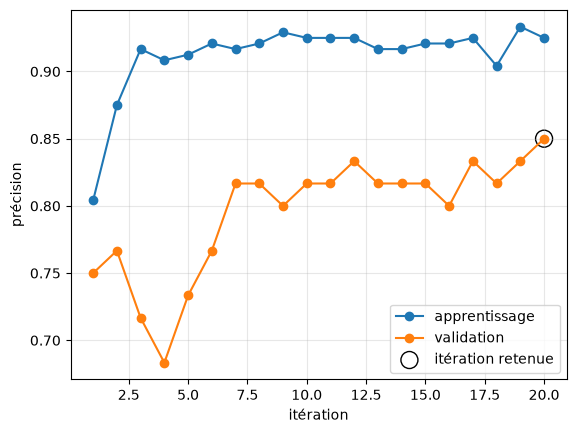

In [25]:
problem, df, y = load_dataset(DATA_DIR / "type_a/cr06_ca03/n0300_rep75-25_noise10.csv")
res = learn_2_mrsort_ambigus(problem, df, y, exclusion="jamais", max_iter=20, patience=20)   # sans arrêt anticipé, pour voir toute la courbe
iters = range(1, len(res["history"]) + 1)
plt.plot(iters, res["history"], marker="o", label="apprentissage")
plt.plot(iters, res["history_val"], marker="o", label="validation")
plt.scatter([res["iteration"] + 1], [res["val_accuracy"]], s=150, facecolors="none", edgecolors="k", label="itération retenue")
plt.xlabel("itération"); plt.ylabel("précision"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 5. Comparaison sur quelques fichiers

Le run complet sur les 72 fichiers dure environ 70 minutes. On compare donc les calendriers sur 5 fichiers choisis pour couvrir les cas difficiles : proportions déséquilibrées, bruit, et le dossier le plus difficile (`type_b/cr10_ca05`). On fait 2 graines par calendrier.

Le temps de lincs augmente pour les fichiers à 8 et 10 critères, mais l'arrêt sur validation réduit le nombre d'itérations. Il faut compter de 30 à 45 minutes.

Comme lincs est aléatoire, des écarts de 1 ou 2 points entre calendriers ne sont pas significatifs.

**Résultats de la version précédente**, pour comparaison : seuil fixe de 0,97 sur la précision d'apprentissage, 2 s de lincs pour tous les fichiers, et pas de jeu de validation. Moyennes sur les 5 fichiers et 2 graines :

| exclusion | train | test | écart train − test | erreur proportion | erreur proportion (discr.) | temps (s) |
|---|---|---|---|---|---|---|
| jamais | 0.934 | 0.843 | 0.091 | 0.125 | 0.112 | 46.7 |
| alternée | 0.935 | 0.828 | 0.107 | 0.099 | 0.074 | 45.0 |
| début | 0.936 | 0.833 | 0.102 | 0.114 | 0.120 | 54.7 |
| toujours | 0.933 | 0.838 | 0.095 | 0.105 | 0.118 | 40.0 |

In [26]:
FILES = ["type_a/cr06_ca03/n0300_rep75-25_noise00.csv",
         "type_a/cr06_ca03/n0300_rep75-25_noise10.csv",
         "type_b/cr08_ca04/n0600_rep75-25_noise00.csv",
         "type_b/cr08_ca04/n0600_rep50-50_noise10.csv",
         "type_b/cr10_ca05/n0600_rep50-50_noise00.csv"]
EXCLUSIONS = ["jamais", "alternée", "début", "toujours"]
SEEDS = [0, 1]

rows = []
for f in FILES:
    for exclusion in EXCLUSIONS:
        for seed in SEEDS:
            rows.append(dict(fichier=f.removesuffix(".csv"), exclusion=exclusion, graine=seed,
                             **evaluate(DATA_DIR / f, exclusion, seed)))

results = pd.DataFrame(rows)
cols = ["train", "val", "test", "petit_segment", "petit_discr", "petit_attendu", "ambigus",
        "iter_retenue", "iterations", "temps"]
results.groupby(["fichier", "exclusion"], sort=False)[cols].mean().round(3)

train    val   test  \
fichier                                 exclusion                        
type_a/cr06_ca03/n0300_rep75-25_noise00 jamais     0.948  0.917  0.892   
                                        alternée   0.966  0.906  0.917   
                                        début      0.951  0.917  0.917   
                                        toujours   0.953  0.927  0.908   
type_a/cr06_ca03/n0300_rep75-25_noise10 jamais     0.841  0.865  0.683   
                                        alternée   0.867  0.865  0.767   
                                        début      0.938  0.917  0.833   
                                        toujours   0.922  0.906  0.808   
type_b/cr08_ca04/n0600_rep75-25_noise00 jamais     0.953  0.906  0.879   
                                        alternée   0.975  0.932  0.904   
                                        début      0.945  0.948  0.904   
                                        toujours   0.945  0.948  0.904   
type_b/cr08_ca04/n0600_rep50-50_noise10 jamais     0.766  0.797  0.758   
                                        alternée   0.790  0.833  0.792   
                                        début      0.853  0.854  0.829   
                                        toujours   0.857  0.859  0.812   
type_b/cr10_ca05/n0600_rep50-50_noise00 jamais     0.876  0.745  0.650   
                                        alternée   0.789  0.724  0.625   
                                        début      0.819  0.760  0.679   
                                        toujours   0.801  0.740  0.688   

                                                   petit_segment  petit_discr  \
fichier                                 exclusion                               
type_a/cr06_ca03/n0300_rep75-25_noise00 jamais             0.411        0.315   
                                        alternée           0.346        0.385   
                                        début              0.388        0.400   
                                        toujours           0.409        0.385   
type_a/cr06_ca03/n0300_rep75-25_noise10 jamais             0.484        0.436   
                                        alternée           0.453        0.431   
                                        début              0.357        0.347   
                                        toujours           0.354        0.380   
type_b/cr08_ca04/n0600_rep75-25_noise00 jamais             0.389        0.371   
                                        alternée           0.393        0.328   
                                        début              0.409        0.417   
                                        toujours           0.409        0.417   
type_b/cr08_ca04/n0600_rep50-50_noise10 jamais             0.438        0.475   
                                        alternée           0.440        0.437   
                                        début              0.436        0.447   
                                        toujours           0.445        0.439   
type_b/cr10_ca05/n0600_rep50-50_noise00 jamais             0.435        0.421   
                                        alternée           0.432        0.451   
                                        début              0.426        0.443   
                                        toujours           0.438        0.464   

                                                   petit_attendu  ambigus  \
fichier                                 exclusion                           
type_a/cr06_ca03/n0300_rep75-25_noise00 jamais              0.25    0.492   
                                        alternée            0.25    0.451   
                                        début               0.25    0.253   
                                        toujours            0.25    0.221   
type_a/cr06_ca03/n0300_rep75-25_noise10 jamais              0.25    0.531   
                                        alternée            0.25    0.432   
                       

In [27]:
results["ecart_train_test"] = results.train - results.test
results["erreur_proportion"] = (results.petit_segment - results.petit_attendu).abs()
results["erreur_proportion_discr"] = (results.petit_discr - results.petit_attendu).abs()
results.groupby("exclusion", sort=False)[["train", "val", "test", "ecart_train_test",
                                          "erreur_proportion", "erreur_proportion_discr", "temps"]].mean().round(3)

,train,val,test,ecart_train_test,erreur_proportion,erreur_proportion_discr,temps
exclusion,,,,,,,
jamais,0.877,0.846,0.772,0.104,0.133,0.095,38.030
alternée,0.878,0.852,0.801,0.077,0.114,0.101,26.449
début,0.901,0.879,0.832,0.069,0.108,0.105,30.545
toujours,0.896,0.876,0.824,0.071,0.108,0.106,27.040
